<a href="https://colab.research.google.com/github/Mitochondrion3000/epic-competiton/blob/main/simple_model/step1_data_table.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Простая интерпретируемая модель. Шаг 1: данные и таблица позиций

**Идея всей серии.** Вместо большой нейросети мы сами придумываем понятные биологические признаки (мотивы промотора,
GC-состав, CpG, повторы…), собираем из них **таблицу** «одна строка = одна позиция генома на одной цепи» и обучаем на ней
простую модель (логистическую регрессию, потом, возможно, неглубокие деревья). Каждый признак можно объяснить словами,
и по весам модели видно, что она считает важным.

| шаг | что делаем | ноутбук |
|---|---|---|
| **1** | **читаем данные, понимаем, что такое «позиция», строим таблицу строк (без признаков)** | **этот** |
| 2 | придумываем и считаем признаки, смотрим, какие из них отличают старты транскрипции | step2 |
| 3 | обучаем простую модель, читаем её веса | step3 |
| 4 | предсказываем весь тест, считаем официальные метрики, сравниваем с CNN | step4 |

Работаем на учебном виде **`jaNemVect1.1`** (*Nematostella vectensis*): у него есть ответы теста, поэтому каждый шаг можно честно проверить.
GPU не нужен: `Runtime → Change runtime type → CPU` подходит.

## 1. Настройки и скачивание

Таблицу, которую соберём в конце, сохраняем на Google Диск (`MyDrive/epic_simple/`), чтобы шаг 2 не пересобирал её заново.

In [1]:
import os, sys, gzip, glob, hashlib, tarfile, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SPECIES = os.environ.get("EPIC_SPECIES", "jaNemVect1.1")
ON_COLAB = "google.colab" in sys.modules
if ON_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
DATA_DIR = os.environ.get("EPIC_DATA_DIR", "/content/epic")                       # сюда распаковываем архив (большой, не храним)
OUT_DIR = os.environ.get("EPIC_OUT_DIR", "/content/drive/MyDrive/epic_simple" if ON_COLAB else "/content/epic_simple")
BASE, FP = f"{DATA_DIR}/{SPECIES}", f"{DATA_DIR}/{SPECIES}/for_participants"
os.makedirs(OUT_DIR, exist_ok=True)

NEG_PER_POS = 10     # сколько случайных отрицательных позиций берём на одну положительную (объяснение в разделе 4)
VAL_FRAC = 0.15      # доля train-whitelist, которую откладываем на валидацию (раздел 3)
SEED = 0

In [2]:
# Скачивание архива вида с Zenodo (doi:10.5281/zenodo.22285753) с проверкой MD5; если уже распакован, ничего не делаем
def download_dataset(species, data_dir):
    if os.path.isdir(f"{data_dir}/{species}"):
        print("датасет уже распакован:", f"{data_dir}/{species}"); return
    import requests
    os.makedirs(data_dir, exist_ok=True)
    rec = requests.get("https://zenodo.org/api/records/22285753", timeout=60).json()
    f = [x for x in rec["files"] if x["key"] == f"{species}.tgz"][0]
    dst, md5 = f"{data_dir}/{species}.tgz", hashlib.md5()
    with requests.get(f["links"]["self"], stream=True, timeout=120) as r, open(dst, "wb") as fh:
        r.raise_for_status()
        for chunk in tqdm(r.iter_content(1 << 22), total=f["size"] // (1 << 22) + 1, desc=f"скачиваю {species}", unit="×4МБ"):
            fh.write(chunk); md5.update(chunk)
    want = f.get("checksum", "md5:").split(":")[-1]
    assert not want or md5.hexdigest() == want, "MD5 не совпал: удалите архив и скачайте снова"
    with tarfile.open(dst) as tf:
        try: tf.extractall(data_dir, filter="data")
        except TypeError: tf.extractall(data_dir)
    os.remove(dst)

download_dataset(SPECIES, DATA_DIR)
for p in sorted(glob.glob(f"{BASE}/**/*", recursive=True)):
    if os.path.isfile(p): print(f"{os.path.getsize(p) / 1e6:8.1f} МБ  {os.path.relpath(p, BASE)}")

датасет уже распакован: /content/epic/jaNemVect1.1
     0.9 МБ  for_participants/csRNA-r1-train-unfiltered.bed.gz
     0.9 МБ  for_participants/csRNA-r1-train.bed.gz
     1.5 МБ  for_participants/csRNA-r1-train.txt.gz
     1.8 МБ  for_participants/csRNA-r2-train-unfiltered.bed.gz
     1.6 МБ  for_participants/csRNA-r2-train.bed.gz
     1.7 МБ  for_participants/csRNA-r2-train.txt.gz
     1.3 МБ  for_participants/csRNA-train.txt.gz
     0.9 МБ  for_participants/rnaseq-r1-train-unfiltered.bed.gz
     0.8 МБ  for_participants/rnaseq-r1-train.bed.gz
     1.5 МБ  for_participants/rnaseq-r1-train.txt.gz
     0.7 МБ  for_participants/rnaseq-r2-train-unfiltered.bed.gz
     0.6 МБ  for_participants/rnaseq-r2-train.bed.gz
     1.4 МБ  for_participants/rnaseq-r2-train.txt.gz
     1.1 МБ  for_participants/rnaseq-train.txt.gz
     0.4 МБ  for_participants/template.test.bed.gz
   214.4 МБ  for_participants/template.test.txt.gz
     1.8 МБ  for_participants/template.train.bed.gz
     0.2 МБ  for_parti

### Какие файлы нам нужны

| файл | что внутри | зачем нам |
|---|---|---|
| `genome/genome.fa.gz` | последовательность ДНК всех контигов. **Строчные буквы** = повторы (мягкая маска) | из неё считаем все признаки |
| `for_participants/whitelist.train.bed.gz` | интервалы train-контигов, где метки известны | только здесь берём обучающие строки |
| `for_participants/csRNA-r1/r2-train.bed.gz` | метки: где начинаются РНК и сколько прочтений, отдельно для двух реплик эксперимента | целевая переменная |
| `for_participants/template.test.bed.gz` | какие позиции теста нужно предсказать и в каком порядке | шаг 4 |
| `ground_truth/csRNA-test.txt.gz` | ответы теста (есть **только** у учебного вида) | шаг 4, честная проверка |

`rnaseq-*` (обычная RNA-seq) мы не используем: на тестовых контигах её нет, а предсказывать нужно только по ДНК.

## 2. Читаем геном и метки

**Геном** храним как массив чисел: `0,1,2,3 = A,C,G,T`, `4 = N` (неизвестная буква). Отдельно храним флаг «строчная буква»:
в этом геноме строчными помечены повторы (мобильные элементы, сателлиты), а это первый кандидат в признаки.

In [3]:
def read_bed(path, ncols):
    names = ["chrom", "start", "end", "name", "score", "strand"][:ncols]
    return pd.read_csv(path, sep="\t", header=None, usecols=range(ncols), names=names, dtype={"chrom": str, "strand": str})

wl_train = read_bed(f"{FP}/whitelist.train.bed.gz", 3)
tpl_test = read_bed(f"{FP}/template.test.bed.gz", 6)
TRAIN_CONTIGS = list(dict.fromkeys(wl_train.chrom))
TEST_CONTIGS = list(dict.fromkeys(tpl_test.chrom))

CODE = np.full(256, 4, np.uint8)               # любой символ, кроме ACGT/acgt -> 4 (N)
for i, b in enumerate("ACGT"):
    CODE[ord(b)] = CODE[ord(b.lower())] = i

def read_genome(path, keep):
    # FASTA -> {контиг: (коды 0..4, флаг строчной буквы)}; читаем только нужные контиги
    seq, low, name, chunks = {}, {}, None, []
    def flush():
        if name in keep:
            raw = np.frombuffer(b"".join(chunks), np.uint8)
            seq[name], low[name] = CODE[raw], raw >= ord("a")
    with gzip.open(path, "rb") as fh:
        for line in tqdm(fh, desc="читаю геном", unit=" строк", mininterval=5):
            if line.startswith(b">"):
                flush(); name, chunks = line[1:].split()[0].decode(), []
            elif name in keep:
                chunks.append(line.rstrip())
    flush()
    return seq, low

t0 = time.time()
SEQ, LOW = read_genome(f"{BASE}/genome/genome.fa.gz", set(TRAIN_CONTIGS) | set(TEST_CONTIGS))
print(f"прочитано {len(SEQ)} контигов, {sum(map(len, SEQ.values())) / 1e6:.1f} Мб за {time.time() - t0:.0f} с")
print(f"train: {len(TRAIN_CONTIGS)} контигов, whitelist {(wl_train.end - wl_train.start).sum() / 1e6:.1f} Мб")
print(f"test : {len(TEST_CONTIGS)} контигов, позиций в шаблоне {(tpl_test.end - tpl_test.start).sum():,}")

прочитано 15 контигов, 268.6 Мб за 13 с
train: 12 контигов, whitelist 155.9 Мб
test : 3 контигов, позиций в шаблоне 72,613,390


**Метки.** Каждая строка BED-файла меток это отрезок `start..end` (до 6 нт подряд) на одной цепи, где во всех позициях одинаковый
счёт прочтений. Разворачиваем отрезки в отдельные позиции, затем объединяем две реплики (`r1`, `r2`):
если позиция есть только в одной реплике, во второй у неё 0. **Целевая величина `tot = r1 + r2`**, именно её оценивает скорер.

In [4]:
def read_counts_bed(path):
    d = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 2, 4, 5], names=["chrom", "start", "end", "count", "strand"],
                    dtype={"chrom": str, "strand": str})
    span = (d.end - d.start).values
    first = np.repeat(np.cumsum(span) - span, span)          # для каждой развёрнутой позиции: где начинается её отрезок
    return pd.DataFrame({"chrom": np.repeat(d.chrom.values, span),
                         "pos": np.repeat(d.start.values, span) + (np.arange(span.sum()) - first),
                         "strand": np.repeat(d.strand.values, span),
                         "count": np.repeat(d["count"].values, span).astype(np.float32)})

REP_FILES = sorted(glob.glob(f"{FP}/csRNA*-r[0-9]-train.bed.gz"))   # у некоторых видов в имени есть ткань: csRNA-Embryo-r1-...
assert REP_FILES, "не нашёл файлы реплик csRNA*-r?-train.bed.gz"
lab = None
for i, path in enumerate(REP_FILES):
    r = read_counts_bed(path).rename(columns={"count": f"r{i + 1}"})
    print(f"{os.path.basename(path)}: {len(r):,} позиций, сумма прочтений {r.iloc[:, -1].sum():,.0f}")
    lab = r if lab is None else lab.merge(r, on=["chrom", "pos", "strand"], how="outer")
REPS = [f"r{i + 1}" for i in range(len(REP_FILES))]
lab[REPS] = lab[REPS].fillna(0)
lab["tot"] = lab[REPS].sum(axis=1)
lab = lab[lab.chrom.isin(TRAIN_CONTIGS)].reset_index(drop=True)

print(f"\nположительных позиций-цепей: {len(lab):,}")
print(f"из них со счётом 1: {(lab.tot == 1).mean():.0%}, со счётом ≥10: {(lab.tot >= 10).mean():.0%}")
if len(REPS) == 2:
    print(f"видны в обеих репликах: {((lab.r1 > 0) & (lab.r2 > 0)).mean():.0%}")

csRNA-r1-train.bed.gz: 97,436 позиций, сумма прочтений 727,611


csRNA-r2-train.bed.gz: 177,755 позиций, сумма прочтений 2,264,390



положительных позиций-цепей: 226,648
из них со счётом 1: 52%, со счётом ≥10: 9%
видны в обеих репликах: 21%


## «Позиция-цепь» и направление чтения

Скорер оценивает **каждую позицию whitelist дважды**: на цепи `+` и на цепи `−`. Поэтому строка нашей таблицы это тройка
`(контиг, позиция, цепь)`.

Самое важное для признаков: **последовательность смотрим всегда по ходу транскрипции**.
* Цепь `+`: РНК идёт вправо, «выше по течению» (upstream, где сидит промотор) это меньшие координаты.
* Цепь `−`: РНК идёт влево, поэтому берём окно справа и **обратно-комплементарно** его разворачиваем.

Тогда для любой строки смещение `−30` означает «30 нт выше старта, там, где ожидается TATA-бокс», независимо от цепи.
Функция ниже возвращает такое ориентированное окно.

In [5]:
LETTERS = np.array(list("ACGTN"))
COMP = np.array([3, 2, 1, 0, 4], np.uint8)        # A<->T, C<->G, N->N

def oriented_window(chrom, pos, strand, a, b):
    # коды оснований на смещениях a..b (включительно) относительно позиции, по ходу транскрипции; за краем контига N
    off = np.arange(a, b + 1)
    g = pos + off if strand == "+" else pos - off
    s = SEQ[chrom]
    out = np.full(len(off), 4, np.uint8)
    ok = (g >= 0) & (g < len(s))
    out[ok] = s[g[ok]] if strand == "+" else COMP[s[g[ok]]]
    return out

def show(chrom, pos, strand, a=-40, b=10):
    w = "".join(LETTERS[oriented_window(chrom, pos, strand, a, b)])
    k = -a
    return w[:k].lower() + "[" + w[k] + "]" + w[k + 1:].lower()   # старт в скобках

print("5 самых сильных стартов train (окно −40..+10, старт в [скобках]):")
for _, r in lab.nlargest(5, "tot").iterrows():
    print(f"  {r.chrom}:{r.pos} {r.strand}  счёт {r.tot:6.0f}   {show(r.chrom, r.pos, r.strand)}")

5 самых сильных стартов train (окно −40..+10, старт в [скобках]):
  NC_064035.1:9182052 -  счёт 767769   cttacccagtttatttatattcgccggaactggttttgtt[G]gaagcgtggt
  NC_064045.1:8411552 +  счёт  43236   gcccctgtggcgcaatggactagcgtgttggacttctaat[T]caaaggttgt
  NC_064040.1:4449621 +  счёт  34660   caaaacacgaataaatggagaatcaaagattcgttagttt[A]gtttagatct
  NC_064036.1:15554118 +  счёт  28128   gactttatcagtcagctcccttcccagaccctgactcatt[A]ctctggtttt
  NC_064041.1:12889556 +  счёт  26047   aagaccgcgtggcctaatggataaggcgtccgacttcgga[T]cggaagattg


## 3. Валидация: какие контиги откладываем

Признаки и модель мы будем подбирать «глазами», поэтому нужна проверка на данных, которые модель не видела.
Откладываем **целые контиги** (а не случайные позиции): соседние позиции в одном промоторе почти одинаковы, и случайное
разбиение дало бы завышенную оценку. Берём контиги жадно, чтобы набрать ~`VAL_FRAC` whitelist с долей положительных,
близкой к средней. Официальный тест (3 хромосомы) не трогаем до шага 4.

In [6]:
wl_bp = (wl_train.end - wl_train.start).groupby(wl_train.chrom, sort=False).sum()
pos_n = lab.groupby("chrom").size().reindex(wl_bp.index, fill_value=0)
RATE = pos_n.sum() / (2 * wl_bp.sum())                          # доля положительных среди всех позиций-цепей whitelist

val, s_bp, s_pos, avail = [], 0, 0, list(wl_bp.index)
while s_bp < VAL_FRAC * wl_bp.sum() and len(avail) > 1:
    best = min(avail, key=lambda c: abs((s_pos + pos_n[c]) / (2 * (s_bp + wl_bp[c])) - RATE))
    val.append(best); avail.remove(best); s_bp += wl_bp[best]; s_pos += pos_n[best]
VAL_CONTIGS = val
split_of = {c: ("val" if c in VAL_CONTIGS else "fit") for c in TRAIN_CONTIGS}

summ = pd.DataFrame({g: {"контигов": sum(v == g for v in split_of.values()),
                         "Мб whitelist": wl_bp[[c for c in wl_bp.index if split_of[c] == g]].sum() / 1e6,
                         "положительных": pos_n[[c for c in wl_bp.index if split_of[c] == g]].sum()} for g in ("fit", "val")}).T
summ["доля положительных"] = summ["положительных"] / (2e6 * summ["Мб whitelist"])
print(summ.to_string(float_format=lambda x: f"{x:.3g}"))
print("val-контиги:", VAL_CONTIGS)
print(f"средняя доля положительных: {RATE:.2e} (это же случайный уровень AUPRC)")

     контигов  Мб whitelist  положительных  доля положительных
fit        10           130       1.89e+05            0.000726
val         2          25.9       3.78e+04            0.000729
val-контиги: ['NC_064042.1', 'NC_064040.1']
средняя доля положительных: 7.27e-04 (это же случайный уровень AUPRC)


## 4. Строки таблицы: все положительные + случайные отрицательные

Позиций-цепей в train-whitelist сотни миллионов, а положительных из них примерно 1 на 1000–2000. Считать признаки для всех
незачем, поэтому берём:
* **все положительные** позиции (`tot > 0`);
* **`NEG_PER_POS` случайных отрицательных** на каждую положительную, равномерно по whitelist и по обеим цепям.

Отрицательные выбираются равномерно, поэтому они честно представляют «типичную» позицию генома. Модель, обученная на такой
выборке, упорядочивает позиции так же, как обученная на полном геноме; меняется только общий сдвиг вероятности, а для
AUPRC и Spearman важен только порядок. Колонка `w` хранит, сколько реальных отрицательных представляет одна выбранная
(пригодится, если захотим откалиброванные вероятности).

In [7]:
rng = np.random.default_rng(SEED)
lab["key"] = lab.pos.values * 2 + (lab.strand.values == "-")   # одно число на позицию-цепь, для быстрой проверки «это положительная?»
POSKEY = {c: np.sort(d.key.values) for c, d in lab.groupby("chrom")}

def sample_negatives(chrom, n):
    iv = wl_train[wl_train.chrom == chrom]
    lens = (iv.end - iv.start).values; cum = np.cumsum(lens)
    out = np.empty(0, np.int64)
    while len(out) < n:
        u = rng.integers(0, cum[-1], 2 * n + 100)                      # случайная точка «внутри whitelist»
        k = np.searchsorted(cum, u, side="right")                      # в какой интервал она попала
        key = (iv.start.values[k] + u - (cum[k] - lens[k])) * 2 + rng.integers(0, 2, len(u))
        key = key[~np.isin(key, POSKEY.get(chrom, []))]                # выбрасываем положительные
        out = np.unique(np.concatenate([out, key]))
    return rng.permutation(out)[:n]

parts = []
for c in tqdm(TRAIN_CONTIGS, desc="отрицательные"):
    n_pos = int(pos_n[c]); n_neg = max(NEG_PER_POS * n_pos, 100)
    key = sample_negatives(c, min(n_neg, 2 * int(wl_bp[c]) - n_pos))
    all_neg = 2 * int(wl_bp[c]) - n_pos                                # сколько всего отрицательных позиций-цепей на контиге
    parts.append(pd.DataFrame({"chrom": c, "pos": key // 2, "strand": np.where(key % 2, "-", "+"),
                               **{r: 0.0 for r in REPS}, "tot": 0.0, "w": all_neg / len(key)}))
pos_rows = lab.drop(columns="key").assign(w=1.0)
table = pd.concat([pos_rows] + parts, ignore_index=True)
table["y"] = (table.tot > 0).astype(np.int8)
table["split"] = table.chrom.map(split_of)
table = table.sort_values(["chrom", "pos", "strand"]).reset_index(drop=True)

print(table.groupby("split").agg(строк=("y", "size"), положительных=("y", "sum")).to_string())
table.sample(8, random_state=1)

         строк  положительных
split                        
fit    2077779         188889
val     415349          37759


,chrom,pos,strand,r1,r2,tot,w,y,split
795261,NC_064036.1,13351322,-,0.0,0.0,0.0,119.986533,0,fit
266425,NC_064035.1,1315918,+,0.0,0.0,0.0,107.870297,0,fit
145924,NC_064034.1,12700152,+,0.0,0.0,0.0,144.186260,0,fit
2246828,NC_064047.1,263079,+,0.0,0.0,0.0,185.943435,0,fit
1675598,NC_064042.1,1601584,-,0.0,0.0,0.0,137.454130,0,val
463001,NC_064035.1,13389569,-,0.0,0.0,0.0,107.870297,0,fit
2133508,NC_064045.1,6119820,+,0.0,0.0,0.0,134.035366,0,fit
1844278,NC_064042.1,14797338,+,0.0,0.0,0.0,137.454130,0,val


## 5. Первый взгляд: отличаются ли старты от случайных позиций?

Два быстрых опыта, чтобы убедиться, что сигнал в последовательности есть, и чтобы показать два вида признаков, которые будем
строить на шаге 2.

**(а) Локальный признак: две буквы на позициях −1 и 0 (сам старт).** У многих организмов старт транскрипции попадает на
мотив *Initiator* (Inr), чаще всего это пиримидин–пурин, `CA` или `TA`, где `A` и есть первая буква РНК. Считаем, во сколько раз
каждый динуклеотид чаще встречается на старте, чем на случайной позиции.

**(б) Региональный признак: GC-состав в окне ±100 нт.** Промоторы часто GC-богаче окружающего генома. Такой признак удобно
считать сразу для всех позиций через накопленную сумму (`cumsum`): число G/C в окне `[p−100, p+100]` равно разности двух
элементов массива. Так же будем считать почти все региональные признаки и на шаге 4 для 72 млн позиций теста.

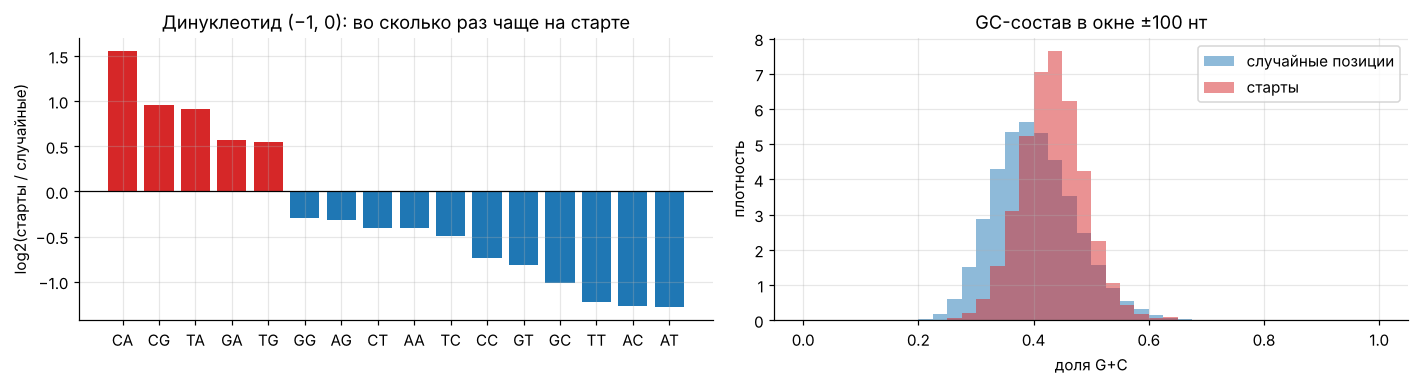

топ-5 динуклеотидов на старте (во сколько раз чаще случайного): {'CA': 2.94, 'CG': 1.94, 'TA': 1.88, 'GA': 1.49, 'TG': 1.46}
медиана GC ±100: старты 0.433, случайные 0.398


In [8]:
# (а) динуклеотид на смещениях −1, 0 (по ходу транскрипции)
def dinuc_at_start(df):
    out = np.empty(len(df), object)
    for (c, st), d in df.groupby(["chrom", "strand"]):
        p = d.pos.values; s = SEQ[c]
        if st == "+": b1, b0 = s[np.clip(p - 1, 0, len(s) - 1)], s[p]
        else:         b1, b0 = COMP[s[np.clip(p + 1, 0, len(s) - 1)]], COMP[s[p]]
        out[df.index.get_indexer(d.index)] = np.char.add(LETTERS[b1], LETTERS[b0])
    return out

table["dinuc_m1_0"] = dinuc_at_start(table)
fit = table[table.split == "fit"]
freq = pd.crosstab(fit.dinuc_m1_0, fit.y, normalize="columns")
freq = freq[~freq.index.str.contains("N")]
enr = (freq[1] / freq[0]).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(enr.index, np.log2(enr.values), color=["tab:red" if v > 0 else "tab:blue" for v in np.log2(enr.values)])
ax[0].axhline(0, color="k", lw=.8)
ax[0].set(title="Динуклеотид (−1, 0): во сколько раз чаще на старте", ylabel="log2(старты / случайные)")

# (б) GC в окне ±100 через cumsum
H = 100
def gc_window(df, h=H):
    out = np.empty(len(df), np.float32)
    for c, d in df.groupby("chrom"):
        s = SEQ[c]; gc = np.concatenate([[0], np.cumsum((s == 1) | (s == 2))])
        ok = np.concatenate([[0], np.cumsum(s < 4)])
        lo, hi = np.clip(d.pos.values - h, 0, len(s)), np.clip(d.pos.values + h + 1, 0, len(s))
        out[df.index.get_indexer(d.index)] = (gc[hi] - gc[lo]) / np.maximum(ok[hi] - ok[lo], 1)
    return out

table["gc_pm100"] = gc_window(table)
fit = table[table.split == "fit"]
bins = np.linspace(0, 1, 41)
for y, col, name in ((0, "tab:blue", "случайные позиции"), (1, "tab:red", "старты")):
    ax[1].hist(fit.gc_pm100[fit.y == y], bins=bins, density=True, alpha=.5, color=col, label=name)
ax[1].set(title=f"GC-состав в окне ±{H} нт", xlabel="доля G+C", ylabel="плотность"); ax[1].legend()
plt.tight_layout(); plt.show()

print("топ-5 динуклеотидов на старте (во сколько раз чаще случайного):", enr.head(5).round(2).to_dict())
print(f"медиана GC ±{H}: старты {fit.gc_pm100[fit.y == 1].median():.3f}, случайные {fit.gc_pm100[fit.y == 0].median():.3f}")

### Как читать эти два графика

* **Левый.** Красные столбцы это динуклеотиды, которые на старте встречаются чаще, чем на случайной позиции, синие реже.
  Если наверху `CA`, `TA` (пиримидин, затем `A`), то это мотив Initiator, и признак «какие буквы на −1 и 0» уже будет полезен модели.
* **Правый.** Если красная гистограмма сдвинута относительно синей, GC-состав окрестности отличает промоторы от фона.
  Насколько сильно, увидим на шаге 3, когда оба признака попадут в модель вместе с остальными.

> Пришли мне вывод этих двух ячеек (числа под графиками и сами графики): от них зависит, какие признаки делать на шаге 2 в первую очередь.

## 6. Сохраняем таблицу для шага 2

In [9]:
meta = dict(SPECIES=SPECIES, VAL_CONTIGS=VAL_CONTIGS, NEG_PER_POS=NEG_PER_POS, RATE=float(RATE), SEED=SEED)
path = f"{OUT_DIR}/{SPECIES}.step1_table.parquet"
table.drop(columns=["dinuc_m1_0", "gc_pm100"]).to_parquet(path, index=False)
pd.Series(meta).to_json(f"{OUT_DIR}/{SPECIES}.step1_meta.json")
print(f"сохранено: {path}  ({len(table):,} строк, {os.path.getsize(path) / 1e6:.1f} МБ)")
print(meta)

сохранено: /content/drive/MyDrive/epic_simple/jaNemVect1.1.step1_table.parquet  (2,493,128 строк, 13.3 МБ)
{'SPECIES': 'jaNemVect1.1', 'VAL_CONTIGS': ['NC_064042.1', 'NC_064040.1'], 'NEG_PER_POS': 10, 'RATE': 0.0007267348696392875, 'SEED': 0}


## Итог шага 1 и что дальше

**Что есть.** Таблица, в которой каждая строка это позиция-цепь train-контига: все старты транскрипции и в 10 раз больше
случайных позиций, с метками (`y` = есть ли старт, `tot` = сила) и разбиением `fit` / `val`. Признаков пока нет.

**Шаг 2: каталог признаков.** Всё считается только из последовательности, все признаки «читаются» биологически:

| группа | признаки | биологический смысл |
|---|---|---|
| сам старт | буквы на −2…+2, мотив Inr (`YR`, `TCA`/`TCT`) | где РНК-полимераза начинает синтез |
| ядро промотора | TATA-бокс в −35…−20, DPE в +25…+35, BRE | места посадки базальных факторов транскрипции |
| окрестность | GC, CpG (наблюдаемое/ожидаемое), поли-A/поли-T в окнах выше и ниже старта | CpG-островки, участки без нуклеосом |
| повторы | доля строчных букв рядом, сама позиция в повторе | повторы чаще молчат (или дают «паразитные» старты) |
| противоположная цепь | те же мотивы на другой цепи в 50–300 нт выше | дивергентная транскрипция (пары старт `+` / старт `−`) |
| частые k-меры | самые обогащённые 6-меры около стартов, найденные по `fit` | мотивы транскрипционных факторов, которых нет в списке выше |